# ML1 - Method Selection

## Main Method: Truncated SVD

Truncated SVD was selected as the main dimensionality reduction method because the customer-product matrix is extremely sparse. SVD can operate directly on sparse matrices without centering the data, making it more suitable for this recommender-system problem than PCA.

The matrix produced in DE5 was 98.32% sparse, so preserving sparsity is important for memory efficiency and scalability.

# ML2 - Selecting the Number of Components

In [1]:
import time
import tracemalloc

import pandas as pd
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt

from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import normalize

train = pd.read_csv("../data/processed/train.csv")

customer_ids = train["Customer ID"].unique()
product_codes = train["StockCode"].unique()

customer_map = {customer: i for i, customer in enumerate(customer_ids)}
product_map = {product: j for j, product in enumerate(product_codes)}

rows = train["Customer ID"].map(customer_map)
cols = train["StockCode"].map(product_map)
values = np.log1p(train["Quantity"])

A = sp.csr_matrix(
    (values, (rows, cols)),
    shape=(len(customer_map), len(product_map))
)

print(A.shape)

(5474, 4529)


## Compare Different Values of k


In [2]:
k_values = [10, 20, 50, 100, 200]

results = []

A_norm = sp.linalg.norm(A)

for k in k_values:
    start = time.time()

    svd = TruncatedSVD(
        n_components=k,
        random_state=42
    )

    customer_factors = svd.fit_transform(A)
    reconstructed = customer_factors @ svd.components_

    fit_time = time.time() - start

    reconstruction_error = (
        np.linalg.norm(A.toarray() - reconstructed)
        / A_norm
    )

    results.append({
        "k": k,
        "Fit Time (seconds)": fit_time,
        "Relative Reconstruction Error": reconstruction_error
    })

    print(
        f"k={k}: "
        f"time={fit_time:.2f}s, "
        f"error={reconstruction_error:.4f}"
    )

k=10: time=0.12s, error=0.7562


k=20: time=0.22s, error=0.6875


k=50: time=0.57s, error=0.5845


k=100: time=1.13s, error=0.4961


k=200: time=2.39s, error=0.3993


In [3]:
results_df = pd.DataFrame(results)
results_df

,k,Fit Time (seconds),Relative Reconstruction Error
0,10,0.123391,0.756233
1,20,0.218031,0.687450
2,50,0.571119,0.584543
3,100,1.125258,0.496108
4,200,2.392955,0.399279


## Reconstruction Error by Number of Components

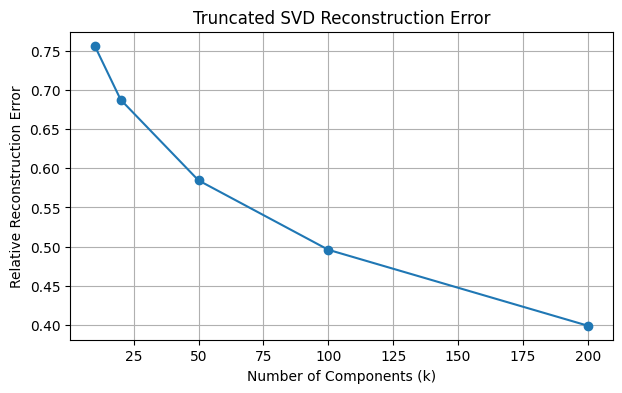

In [4]:
plt.figure(figsize=(7, 4))
plt.plot(
    results_df["k"],
    results_df["Relative Reconstruction Error"],
    marker="o"
)

plt.xlabel("Number of Components (k)")
plt.ylabel("Relative Reconstruction Error")
plt.title("Truncated SVD Reconstruction Error")
plt.grid(True)
plt.show()

### Choice of k

Reconstruction error improves as k increases, but the gains become smaller at higher values. **k = 100** was chosen as a good balance between accuracy, speed, and model size.

# ML3 - Product Recommendations

In [5]:
final_svd = TruncatedSVD(
    n_components=100,
    random_state=42
)

customer_factors = final_svd.fit_transform(A)

product_vectors = normalize(
    final_svd.components_.T
)

print("Customer factors shape:", customer_factors.shape)
print("Product vectors shape:", product_vectors.shape)

Customer factors shape: (5474, 100)
Product vectors shape: (4529, 100)


## Find Similar Products

In [6]:
def similar_products(product_code, n=10):
    if product_code not in product_map:
        return []

    j = product_map[product_code]

    similarities = product_vectors @ product_vectors[j]
    similarities[j] = -np.inf

    top_indices = np.argsort(-similarities)[:n]

    index_to_product = {
        index: product
        for product, index in product_map.items()
    }

    return [
        (index_to_product[i], similarities[i])
        for i in top_indices
    ]

In [7]:
example_product = train["StockCode"].iloc[0]

print("Example product:", example_product)

similar_products(example_product)

Example product: 85048


[('90169', np.float64(0.7198956437762556)),
 ('90156', np.float64(0.7192305957524416)),
 ('90202D', np.float64(0.7129100024285385)),
 ('23427', np.float64(0.7114865889937505)),
 ('22283', np.float64(0.681825023098854)),
 ('23269', np.float64(0.6771481378726775)),
 ('22576', np.float64(0.6739703306400483)),
 ('90075', np.float64(0.6706570284203546)),
 ('90155', np.float64(0.6642830105835863)),
 ('84706F', np.float64(0.6638379603306489))]

## Recommend Products for a Customer

In [8]:
def recommend_for_customer(customer_id, n=10):
    if customer_id not in customer_map:
        return []

    customer_rows = train[train["Customer ID"] == customer_id]

    bought_products = [
        p for p in customer_rows["StockCode"].unique()
        if p in product_map
    ]

    if not bought_products:
        return []

    bought_indices = [product_map[p] for p in bought_products]

    customer_profile = product_vectors[bought_indices].mean(axis=0)

    scores = product_vectors @ customer_profile

    scores[bought_indices] = -np.inf

    top_indices = np.argsort(-scores)[:n]

    index_to_product = {
        index: product
        for product, index in product_map.items()
    }

    return [
        (index_to_product[i], scores[i])
        for i in top_indices
    ]

In [9]:
example_customer = train["Customer ID"].iloc[0]

# R4: refer to customers by anonymised matrix index, never by their real ID
print("Example customer (anonymised index):", customer_map[example_customer])

recommend_for_customer(example_customer)

Example customer (anonymised index): 0


[('22134', np.float64(0.10528370013621302)),
 ('84993B', np.float64(0.10523259856169118)),
 ('85215', np.float64(0.10389403564096147)),
 ('22747', np.float64(0.09785450076728389)),
 ('21945', np.float64(0.09658185800713205)),
 ('90084', np.float64(0.09625603542604944)),
 ('47504G', np.float64(0.09603118002357097)),
 ('21942', np.float64(0.09463544003256988)),
 ('17090D', np.float64(0.09460116271163065)),
 ('22476', np.float64(0.09437076350454318))]

# ML4 - Recommendation Evaluation


In [10]:
test_new = pd.read_csv("../data/processed/test_new.csv")

test_customers = test_new["Customer ID"].unique()

print(test_new.shape)

(72876, 8)


## Customers We Can Evaluate

The model can only score customers that appear in the training matrix. This set is
fixed once, here, and every hit rate below is measured over exactly these customers.


In [11]:
eligible_customers = [
    customer_id
    for customer_id in test_customers
    if customer_id in customer_map
]

print("Eligible customers:", len(eligible_customers))

Eligible customers: 1927


## Best-Seller Baseline

In [12]:
best_sellers = (
    train.groupby("StockCode")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .index
    .tolist()
)

print(best_sellers)

['84077', '21212', '85123A', '85099B', '23166', '84879', '17003', '22197', '21977', '84991']


## SVD Hit Rate@10


In [13]:
hits = 0
evaluated_customers = 0

for customer_id in test_customers:
    if customer_id not in customer_map:
        continue

    held_out_products = set(
        test_new.loc[
            test_new["Customer ID"] == customer_id,
            "StockCode"
        ]
    )

    recommendations = recommend_for_customer(customer_id, n=10)
    recommended_products = {product for product, score in recommendations}

    if not recommendations:
        continue

    evaluated_customers += 1

    if held_out_products.intersection(recommended_products):
        hits += 1

svd_hit_rate = hits / evaluated_customers

print("Customers evaluated:", evaluated_customers)
print("SVD hits:", hits)
print(f"SVD Hit Rate@10: {svd_hit_rate:.4f}")

Customers evaluated: 1927
SVD hits: 397
SVD Hit Rate@10: 0.2060


## Best-Seller Baseline Hit Rate@10 (same customers)

Measured over the same eligible customers as the model, and excluding products a
customer has already bought, so the two numbers are directly comparable.


In [14]:
baseline_hits = 0

for customer_id in eligible_customers:
    held_out_products = set(
        test_new.loc[
            test_new["Customer ID"] == customer_id,
            "StockCode"
        ]
    )

    already_bought = set(
        train.loc[
            train["Customer ID"] == customer_id,
            "StockCode"
        ]
    )

    customer_best_sellers = [
        product
        for product in (
            train.groupby("StockCode")["Quantity"]
            .sum()
            .sort_values(ascending=False)
            .index
        )
        if product not in already_bought
    ][:10]

    if held_out_products.intersection(customer_best_sellers):
        baseline_hits += 1

baseline_hit_rate = baseline_hits / len(eligible_customers)

print("Customers evaluated:", len(eligible_customers))
print("Baseline hits:", baseline_hits)
print(f"Baseline Hit Rate@10: {baseline_hit_rate:.4f}")

Customers evaluated: 1927
Baseline hits: 333
Baseline Hit Rate@10: 0.1728


### Footnote: Baseline Over All Test Customers

This is the same baseline measured over all 2,305 test customers, including those
with no training history. It is **not** comparable with the model, which can only
score the 1,927 customers present in the training matrix. It is kept for reference;
the figure used in the comparison table is the one above.


In [15]:
hits = 0
evaluated_customers = 0

for customer_id in test_customers:
    held_out_products = set(
        test_new.loc[
            test_new["Customer ID"] == customer_id,
            "StockCode"
        ]
    )

    if not held_out_products:
        continue

    evaluated_customers += 1

    if held_out_products.intersection(best_sellers):
        hits += 1

baseline_hit_rate_all_test = hits / evaluated_customers

print("Customers evaluated:", evaluated_customers)
print("Baseline hits:", hits)
print(f"Baseline Hit Rate@10: {baseline_hit_rate_all_test:.4f}")

Customers evaluated: 2305
Baseline hits: 433
Baseline Hit Rate@10: 0.1879


### Evaluation Result

The SVD recommender achieved a Hit Rate@10 of **20.60%**, compared with **17.28%** for the best-seller baseline.

This shows that the personalized SVD recommendations perform better than recommending the most popular products, by 3.3 percentage points.

## Nightly Recommendation Job Timing

In [16]:
start = time.time()

all_recommendations = {}

for customer_id in eligible_customers:
    all_recommendations[customer_id] = recommend_for_customer(
        customer_id,
        n=10
    )

nightly_job_time = time.time() - start

print("Customers scored:", len(eligible_customers))
print(f"Nightly recommendation job time: {nightly_job_time:.2f} seconds")

Customers scored: 1927
Nightly recommendation job time: 1.56 seconds


### Runtime Result

The model generated top-10 recommendations for 1,927 customers in **1.56 seconds**, showing that the compressed SVD representation can support a fast nightly recommendation job.

# ML5 - PCA vs SVD Comparison

In [17]:
start = time.time()

pca = PCA(
    n_components=100,
    svd_solver="arpack",
    random_state=42
)

pca_customer_factors = pca.fit_transform(A)

pca_fit_time = time.time() - start

print(f"PCA fit time: {pca_fit_time:.2f} seconds")
print(
    "Explained variance:",
    pca.explained_variance_ratio_.sum()
)

PCA fit time: 0.45 seconds
Explained variance: 0.7481185136021157


## Peak Memory During Fit

In [18]:
# SVD peak memory
tracemalloc.start()

start = time.time()

svd_memory_test = TruncatedSVD(
    n_components=100,
    random_state=42
)

svd_memory_test.fit(A)

svd_fit_time_memory = time.time() - start

current, peak = tracemalloc.get_traced_memory()
svd_peak_memory_mb = peak / (1024 ** 2)

tracemalloc.stop()

print(f"SVD fit time: {svd_fit_time_memory:.2f} seconds")
print(f"SVD peak memory: {svd_peak_memory_mb:.2f} MB")

SVD fit time: 1.01 seconds
SVD peak memory: 17.70 MB


In [19]:
tracemalloc.start()

start = time.time()

pca_memory_test = PCA(
    n_components=100,
    svd_solver="arpack",
    random_state=42
)

pca_memory_test.fit(A)

pca_fit_time_memory = time.time() - start

current, peak = tracemalloc.get_traced_memory()
pca_peak_memory_mb = peak / (1024 ** 2)

tracemalloc.stop()

print(f"PCA fit time: {pca_fit_time_memory:.2f} seconds")
print(f"PCA peak memory: {pca_peak_memory_mb:.2f} MB")

PCA fit time: 0.48 seconds
PCA peak memory: 17.92 MB


## Storage Size: PCA vs SVD


In [20]:
pca_storage_mb = (
    pca_customer_factors.nbytes
    + pca.components_.nbytes
) / (1024 ** 2)

print(f"PCA stored factors: {pca_storage_mb:.2f} MB")

PCA stored factors: 7.63 MB


In [21]:
svd_storage_mb = (
    customer_factors.nbytes
    + final_svd.components_.nbytes
) / (1024 ** 2)

print(f"SVD stored factors: {svd_storage_mb:.2f} MB")

SVD stored factors: 7.63 MB


## PCA Recommendation Evaluation

In [22]:
pca_product_vectors = normalize(pca.components_.T)

def recommend_for_customer_pca(customer_id, n=10):
    if customer_id not in customer_map:
        return []

    customer_rows = train[train["Customer ID"] == customer_id]

    bought_products = [
        p for p in customer_rows["StockCode"].unique()
        if p in product_map
    ]

    if not bought_products:
        return []

    bought_indices = [product_map[p] for p in bought_products]

    customer_profile = pca_product_vectors[bought_indices].mean(axis=0)

    scores = pca_product_vectors @ customer_profile
    scores[bought_indices] = -np.inf

    top_indices = np.argsort(-scores)[:n]

    index_to_product = {
        index: product
        for product, index in product_map.items()
    }

    return [
        (index_to_product[i], scores[i])
        for i in top_indices
    ]

In [23]:
pca_hits = 0

for customer_id in eligible_customers:
    held_out_products = set(
        test_new.loc[
            test_new["Customer ID"] == customer_id,
            "StockCode"
        ]
    )

    recommendations = recommend_for_customer_pca(
        customer_id,
        n=10
    )

    recommended_products = {
        product for product, score in recommendations
    }

    if held_out_products.intersection(recommended_products):
        pca_hits += 1

pca_hit_rate = pca_hits / len(eligible_customers)

print("Customers evaluated:", len(eligible_customers))
print("PCA hits:", pca_hits)
print(f"PCA Hit Rate@10: {pca_hit_rate:.4f}")

Customers evaluated: 1927
PCA hits: 388
PCA Hit Rate@10: 0.2013


## Interpret Component 1


In [24]:
# Map product codes to a representative description
product_descriptions = (
    train.groupby("StockCode")["Description"]
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else x.iloc[0])
    .to_dict()
)

index_to_product = {
    index: product
    for product, index in product_map.items()
}

In [25]:
svd_component1 = final_svd.components_[0]

svd_top_indices = np.argsort(-np.abs(svd_component1))[:10]

print("Top products for SVD Component 1:")

for i in svd_top_indices:
    code = index_to_product[i]
    print(
        code,
        product_descriptions.get(code, ""),
        svd_component1[i]
    )

Top products for SVD Component 1:
85123A WHITE HANGING HEART T-LIGHT HOLDER 0.23068171181065622
85099B JUMBO BAG RED RETROSPOT 0.2115735913920984
21212 PACK OF 72 RETROSPOT CAKE CASES 0.18781779700394824
20725 LUNCH BAG RED RETROSPOT 0.15954043315116204
22423 REGENCY CAKESTAND 3 TIER 0.133839802159745
84879 ASSORTED COLOUR BIRD ORNAMENT 0.12576208294517527
84991 60 TEATIME FAIRY CAKE CASES 0.12528699762181233
22386 JUMBO BAG PINK POLKADOT 0.11085184861043876
22197 SMALL POPCORN HOLDER 0.10831392715952978
20724 RED RETROSPOT CHARLOTTE BAG 0.10154593574147695


In [26]:
pca_component1 = pca.components_[0]

pca_top_indices = np.argsort(-np.abs(pca_component1))[:10]

print("\nTop products for PCA Component 1:")

for i in pca_top_indices:
    code = index_to_product[i]
    print(
        code,
        product_descriptions.get(code, ""),
        pca_component1[i]
    )


Top products for PCA Component 1:
85123A WHITE HANGING HEART T-LIGHT HOLDER 0.22401868913163936
85099B JUMBO BAG RED RETROSPOT 0.21587695981493213
21212 PACK OF 72 RETROSPOT CAKE CASES 0.19024675280821882
20725 LUNCH BAG RED RETROSPOT 0.16387962473718778
22423 REGENCY CAKESTAND 3 TIER 0.13522190109199586
84991 60 TEATIME FAIRY CAKE CASES 0.12666941813755261
84879 ASSORTED COLOUR BIRD ORNAMENT 0.11845134734185128
22386 JUMBO BAG PINK POLKADOT 0.11408494799455979
22197 SMALL POPCORN HOLDER 0.10914126916360319
20724 RED RETROSPOT CHARLOTTE BAG 0.10534585305992063


### Component 1 Interpretation

Both methods load component 1 on the same high-volume products, so component 1
represents overall purchasing activity rather than a distinct taste.


In [27]:
# Fit time and peak memory are taken from the profiled fits above, so the two
# rows come from one consistent measurement rather than two separate runs.

svd_error_k100 = results_df.loc[
    results_df["k"] == 100,
    "Relative Reconstruction Error"
].iloc[0]

comparison = pd.DataFrame({
    "Measure": [
        "k used",
        "Fit time (seconds)",
        "Peak memory during fit (MB)",
        "Stored factors (MB)",
        "Variance explained / Reconstruction error",
        "Hit Rate@10",
        "Best-seller baseline Hit Rate@10",
        "What component 1 represents"
    ],
    "PCA": [
        100,
        round(pca_fit_time_memory, 2),
        round(pca_peak_memory_mb, 2),
        round(pca_storage_mb, 2),
        f"{pca.explained_variance_ratio_.sum():.2%} explained variance",
        round(pca_hit_rate, 4),
        round(baseline_hit_rate, 4),
        "Overall purchasing activity / popular products"
    ],
    "Truncated SVD": [
        100,
        round(svd_fit_time_memory, 2),
        round(svd_peak_memory_mb, 2),
        round(svd_storage_mb, 2),
        f"{svd_error_k100:.4f} relative reconstruction error",
        round(svd_hit_rate, 4),
        round(baseline_hit_rate, 4),
        "Overall purchasing activity / popular products"
    ]
})

comparison


,Measure,PCA,Truncated SVD
0,k used,100,100
1,Fit time (seconds),0.48,1.01
2,Peak memory during fit (MB),17.92,17.7
3,Stored factors (MB),7.63,7.63
4,Variance explained / Reconstruction error,74.81% explained variance,0.4961 relative reconstruction error
5,Hit Rate@10,0.2013,0.206
6,Best-seller baseline Hit Rate@10,0.1728,0.1728
7,What component 1 represents,Overall purchasing activity / popular products,Overall purchasing activity / popular products


## PCA vs SVD Results

Both PCA and SVD produced very similar recommendation accuracy, with SVD achieving a slightly higher Hit Rate@10.

SVD is the preferred method because it works directly with sparse data and avoids the centering step required by PCA.